PyTorch: 2.14.1+cu130 | urządzenie: cuda
GPU: Tesla T4


100%|██████████| 170M/170M [32:16<00:00, 88.0kB/s]


Klasy: ['airplane', 'automobile', 'bird', 'cat', 'deer', 'dog', 'frog', 'horse', 'ship', 'truck']
Trening: 45000 | Walidacja: 5000 | Test: 10000

MLP parametry:                 1,707,274
CNN część splotowa parametry:     65,952
CNN głowica parametry:         1,051,402
CNN razem parametry:           1,117,354

=== TESTY KONTROLNE ===
blok 0 (4, 32, 16, 16)
blok 1 (4, 64, 8, 8)
logity (4, 10)
MLP: strata na starcie 2.317 (oczekiwane ok. 2.303)
CNN: strata na starcie 2.309 (oczekiwane ok. 2.303)
przeuczenie 1 paczki | krok   0 | strata 2.3552
przeuczenie 1 paczki | krok  25 | strata 0.0108
przeuczenie 1 paczki | krok  50 | strata 0.0011
przeuczenie 1 paczki | krok  75 | strata 0.0014
przeuczenie 1 paczki | krok 100 | strata 0.0004

== TRENING: MLP ==
  epoka  1 | strata tr 1.448 wal 1.526 | acc tr 48.75% wal 46.30%
  epoka  2 | strata tr 1.335 wal 1.459 | acc tr 53.11% wal 49.10%
  epoka  3 | strata tr 1.204 wal 1.392 | acc tr 57.59% wal 51.36%
  epoka  4 | strata tr 1.152 wal 1.418 | acc

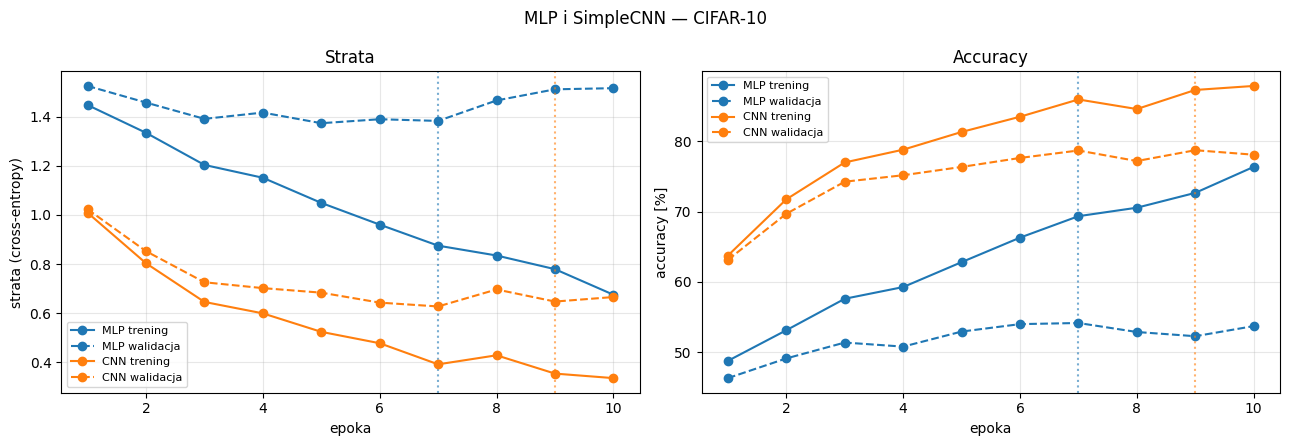

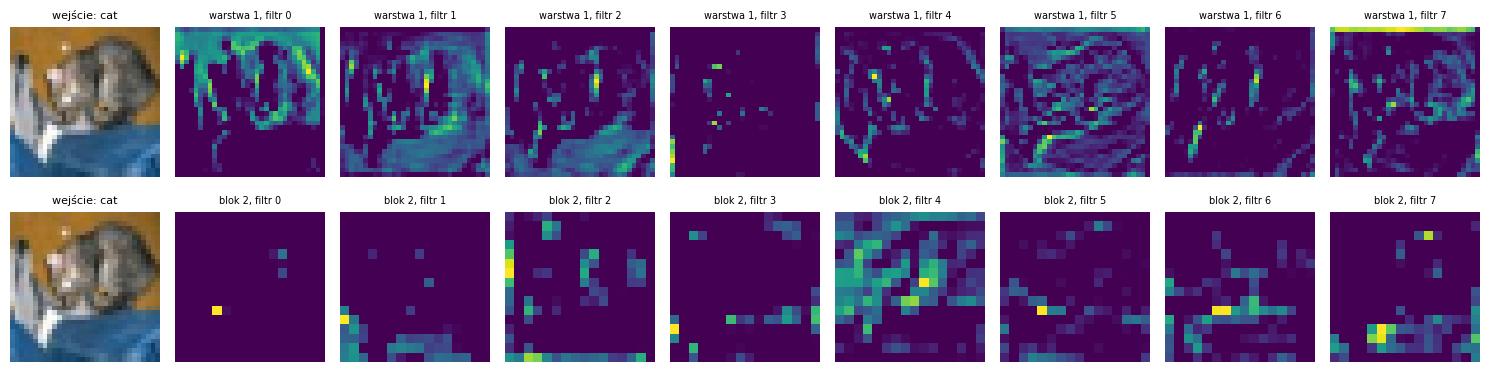


=== ZAKRES DODATKOWY A: WPŁYW LICZBY FILTRÓW ===

== SimpleCNN c1=16, c2=32 ==
  epoka  1 | strata tr 1.034 wal 1.040 | acc tr 62.82% wal 62.58%
  epoka  2 | strata tr 0.843 wal 0.894 | acc tr 70.38% wal 68.60%
  epoka  3 | strata tr 0.684 wal 0.766 | acc tr 75.81% wal 72.66%
  epoka  4 | strata tr 0.668 wal 0.766 | acc tr 76.00% wal 72.72%
  epoka  5 | strata tr 0.585 wal 0.738 | acc tr 78.86% wal 73.86%
  epoka  6 | strata tr 0.526 wal 0.695 | acc tr 81.04% wal 75.60%
  epoka  7 | strata tr 0.475 wal 0.686 | acc tr 83.08% wal 76.42%
  epoka  8 | strata tr 0.500 wal 0.760 | acc tr 82.47% wal 75.66%
  epoka  9 | strata tr 0.408 wal 0.691 | acc tr 85.74% wal 76.70%
  epoka 10 | strata tr 0.351 wal 0.670 | acc tr 87.78% wal 77.20%

== SimpleCNN c1=64, c2=128 ==
  epoka  1 | strata tr 1.105 wal 1.120 | acc tr 60.05% wal 58.88%
  epoka  2 | strata tr 0.907 wal 0.932 | acc tr 67.86% wal 66.98%
  epoka  3 | strata tr 0.788 wal 0.851 | acc tr 71.90% wal 69.98%
  epoka  4 | strata tr 0.676 wa

In [1]:
# === 1. IMPORTY, URZĄDZENIE I KONFIGURACJA ===
import copy, math, time
import torch
import torch.nn as nn
from torch.utils.data import DataLoader, Subset
import torchvision
from torchvision import transforms
import matplotlib.pyplot as plt

CFG = {
    "epochs": 10,        # budżet epok, ten sam dla obu modeli
    "lr": 1e-3,          # learning rate (Adam)
    "batch_size": 128,
    "n_val": 5000,       # rozmiar zbioru walidacyjnego wydzielonego z treningu
    "augment": False,    # augmentacja tylko na zbiorze treningowym
    "seed": 42,
}

torch.manual_seed(CFG["seed"])
device = "cuda" if torch.cuda.is_available() else "cpu"
print("PyTorch:", torch.__version__, "| urządzenie:", device)
if device == "cuda":
    print("GPU:", torch.cuda.get_device_name(0))
else:
    print("UWAGA: Uruchomiono na CPU! Zmień środowisko na GPU (Runtime -> Change runtime type -> GPU).")

# === 2. DANE: CIFAR-10 Z PODZIAŁEM TRENING / WALIDACJA / TEST ===
mean = (0.4914, 0.4822, 0.4465)
std  = (0.2470, 0.2435, 0.2616)
tf_eval = transforms.Compose([transforms.ToTensor(), transforms.Normalize(mean, std)])
tf_train = transforms.Compose(
    ([transforms.RandomCrop(32, padding=4), transforms.RandomHorizontalFlip()] if CFG["augment"] else [])
    + [transforms.ToTensor(), transforms.Normalize(mean, std)]
)

train_full_aug  = torchvision.datasets.CIFAR10("./data", train=True,  download=True, transform=tf_train)
train_full_eval = torchvision.datasets.CIFAR10("./data", train=True,  download=True, transform=tf_eval)
test_ds         = torchvision.datasets.CIFAR10("./data", train=False, download=True, transform=tf_eval)
classes = train_full_eval.classes

g = torch.Generator().manual_seed(CFG["seed"])
perm = torch.randperm(len(train_full_eval), generator=g).tolist()
val_idx, train_idx = perm[:CFG["n_val"]], perm[CFG["n_val"]:]

train_ds = Subset(train_full_aug, train_idx)
val_ds   = Subset(train_full_eval, val_idx)

train_dl      = DataLoader(train_ds, batch_size=CFG["batch_size"], shuffle=True,  num_workers=2)
train_eval_dl = DataLoader(Subset(train_full_eval, train_idx), batch_size=256, shuffle=False, num_workers=2)
val_dl        = DataLoader(val_ds,   batch_size=256, shuffle=False, num_workers=2)
test_dl       = DataLoader(test_ds,  batch_size=256, shuffle=False, num_workers=2)

print("Klasy:", classes)
print(f"Trening: {len(train_ds)} | Walidacja: {len(val_ds)} | Test: {len(test_ds)}")

# === 3. DEFINICJE MODELI: MLP I SimpleCNN ===
class MLP(nn.Module):
    def __init__(self, in_dim=3*32*32, hidden=(512, 256), n_classes=10):
        super().__init__()
        self.net = nn.Sequential(
            nn.Flatten(),
            nn.Linear(in_dim, hidden[0]), nn.ReLU(),
            nn.Linear(hidden[0], hidden[1]), nn.ReLU(),
            nn.Linear(hidden[1], n_classes),
        )
    def forward(self, x):
        return self.net(x)

def block(cin, cout):
    return nn.Sequential(
        nn.Conv2d(cin, cout, 3, padding=1), nn.BatchNorm2d(cout), nn.ReLU(),
        nn.Conv2d(cout, cout, 3, padding=1), nn.BatchNorm2d(cout), nn.ReLU(),
        nn.MaxPool2d(2),
    )

class SimpleCNN(nn.Module):
    def __init__(self, c1=32, c2=64, n_classes=10):
        super().__init__()
        self.features = nn.Sequential(block(3, c1), block(c1, c2))
        self.classifier = nn.Sequential(
            nn.Flatten(), nn.Linear(c2*8*8, 256), nn.ReLU(),
            nn.Dropout(0.3), nn.Linear(256, n_classes),
        )
    def forward(self, x):
        return self.classifier(self.features(x))

def count_params(m):
    return sum(p.numel() for p in m.parameters() if p.requires_grad)

mlp_tmp, cnn_tmp = MLP(), SimpleCNN()
print(f"\nMLP parametry:                {count_params(mlp_tmp):>10,}")
print(f"CNN część splotowa parametry: {count_params(cnn_tmp.features):>10,}")
print(f"CNN głowica parametry:        {count_params(cnn_tmp.classifier):>10,}")
print(f"CNN razem parametry:          {count_params(cnn_tmp):>10,}")

# === 4. TESTY KONTROLNE PRZED TRENINGIEM ===
print("\n=== TESTY KONTROLNE ===")
x_test_shape = torch.randn(4, 3, 32, 32)
for name, layer in cnn_tmp.features.named_children():
    x_test_shape = layer(x_test_shape)
    print("blok", name, tuple(x_test_shape.shape))
print("logity", tuple(cnn_tmp.classifier(x_test_shape).shape))

crit = nn.CrossEntropyLoss()
xb, yb = next(iter(train_dl))
for name, m in [("MLP", MLP()), ("CNN", SimpleCNN())]:
    m = m.to(device).eval()
    with torch.no_grad():
        print(f"{name}: strata na starcie {crit(m(xb.to(device)), yb.to(device)).item():.3f} (oczekiwane ok. {math.log(10):.3f})")

m_overfit = SimpleCNN().to(device)
opt_overfit = torch.optim.Adam(m_overfit.parameters(), lr=1e-3)
x32, y32 = xb[:32].to(device), yb[:32].to(device)
m_overfit.train()
for step in range(101):
    opt_overfit.zero_grad()
    loss = crit(m_overfit(x32), y32)
    loss.backward()
    opt_overfit.step()
    if step % 25 == 0:
        print(f"przeuczenie 1 paczki | krok {step:3d} | strata {loss.item():.4f}")

# === 5. FUNKCJE TRENINGU I EWALUACJI ===
def sync():
    if device == "cuda":
        torch.cuda.synchronize()

def train_one_epoch(model, dl, opt, crit):
    model.train()
    s = n = 0
    for xb, yb in dl:
        xb, yb = xb.to(device), yb.to(device)
        opt.zero_grad()
        loss = crit(model(xb), yb)
        loss.backward()
        opt.step()
        s += loss.item() * yb.size(0)
        n += yb.size(0)
    return s / n

@torch.no_grad()
def evaluate(model, dl, crit):
    model.eval()
    s = c = n = 0
    for xb, yb in dl:
        xb, yb = xb.to(device), yb.to(device)
        out = model(xb)
        s += crit(out, yb).item() * yb.size(0)
        c += (out.argmax(1) == yb).sum().item()
        n += yb.size(0)
    return s / n, c / n

def fit(model, cfg=CFG):
    torch.manual_seed(cfg["seed"])
    model = model.to(device)
    crit = nn.CrossEntropyLoss()
    opt = torch.optim.Adam(model.parameters(), lr=cfg["lr"])
    hist = {k: [] for k in ["train_loss", "train_acc", "val_loss", "val_acc"]}
    best = {"val_acc": -1.0, "epoch": 0, "state": None}
    train_time = eval_time = 0.0
    for epoch in range(1, cfg["epochs"] + 1):
        sync(); t0 = time.time()
        train_one_epoch(model, train_dl, opt, crit)
        sync(); t1 = time.time()
        tr_loss, tr_acc = evaluate(model, train_eval_dl, crit)
        va_loss, va_acc = evaluate(model, val_dl, crit)
        sync(); t2 = time.time()
        train_time += t1 - t0
        eval_time += t2 - t1
        for k, v in zip(hist, [tr_loss, tr_acc, va_loss, va_acc]):
            hist[k].append(v)
        if va_acc > best["val_acc"]:
            best = {"val_acc": va_acc, "epoch": epoch, "state": copy.deepcopy(model.state_dict())}
        print(f"  epoka {epoch:2d} | strata tr {tr_loss:.3f} wal {va_loss:.3f} | acc tr {tr_acc*100:5.2f}% wal {va_acc*100:5.2f}%")
    model.load_state_dict(best["state"])
    return {"model": model, "hist": hist, "best": best, "train_time": train_time, "eval_time": eval_time}

# === 6. TRENING GŁÓWNY: MLP vs SimpleCNN ===
print("\n== TRENING: MLP ==")
res_mlp = fit(MLP())

print("\n== TRENING: SimpleCNN ==")
res_cnn = fit(SimpleCNN())

# === 7. KOŃCOWA OCENA NA ZBIORZE TESTOWYM (ZAKRES OBOWIĄZKOWY) ===
crit = nn.CrossEntropyLoss()
rows = []
for name, r in [("MLP", res_mlp), ("CNN", res_cnn)]:
    m, h, b = r["model"], r["hist"], r["best"]
    _, test_acc = evaluate(m, test_dl, crit)
    i = b["epoch"] - 1
    rows.append((name, count_params(m), b["epoch"], h["train_acc"][i], b["val_acc"],
                 h["train_acc"][i] - b["val_acc"], test_acc, r["train_time"], r["eval_time"]))

print("\n=== WYNIKI KOŃCOWE (ZAKRES OBOWIĄZKOWY) ===")
print(f"{'model':5} | {'parametry':>10} | {'epoka':>5} | {'acc tr':>7} | {'acc wal':>7} | {'przerwa':>7} | {'acc test':>8} | {'czas tr [s]':>11} | {'czas ew [s]':>11}")
print("-" * 100)
for n, p, e, tr, va, gap, te, t_tr, t_ev in rows:
    print(f"{n:5} | {p:>10,} | {e:>5} | {tr*100:6.2f}% | {va*100:6.2f}% | {gap*100:6.2f}% | {te*100:7.2f}% | {t_tr:>11.1f} | {t_ev:>11.1f}")
print(f"\nCNN: część splotowa {count_params(res_cnn['model'].features):,}, głowica {count_params(res_cnn['model'].classifier):,}")
print("Klasyfikator losowy: 10.00%")

# === 8. WYKRES KRZYWYCH UCZENIA ===
fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(13, 4.5))
for name, r, color in [("MLP", res_mlp, "tab:blue"), ("CNN", res_cnn, "tab:orange")]:
    h = r["hist"]
    ep = range(1, len(h["train_loss"]) + 1)
    ax1.plot(ep, h["train_loss"], "-o", color=color, label=f"{name} trening")
    ax1.plot(ep, h["val_loss"], "--o", color=color, label=f"{name} walidacja")
    ax2.plot(ep, [a*100 for a in h["train_acc"]], "-o", color=color, label=f"{name} trening")
    ax2.plot(ep, [a*100 for a in h["val_acc"]], "--o", color=color, label=f"{name} walidacja")
    for ax in (ax1, ax2):
        ax.axvline(r["best"]["epoch"], color=color, ls=":", alpha=0.6)
ax1.set(xlabel="epoka", ylabel="strata (cross-entropy)", title="Strata")
ax2.set(xlabel="epoka", ylabel="accuracy [%]", title="Accuracy")
for ax in (ax1, ax2):
    ax.grid(alpha=0.3)
    ax.legend(fontsize=8)
plt.suptitle("MLP i SimpleCNN — CIFAR-10")
plt.tight_layout()
plt.savefig("krzywe_uczenia.png", dpi=150)
plt.show()

# === 9. MAPY CECH PIERWSZEJ I GŁĘBSZEJ WARSTWY SPLOTOWEJ ===
mean_t = torch.tensor(mean).view(3, 1, 1)
std_t  = torch.tensor(std).view(3, 1, 1)
def denorm(img):
    return (img * std_t + mean_t).clamp(0, 1).permute(1, 2, 0).numpy()

cnn = res_cnn["model"].eval()
img, label = test_ds[0]
x = img.unsqueeze(0).to(device)
with torch.no_grad():
    maps1 = torch.relu(cnn.features[0][0](x))[0].cpu()
    after_block1 = cnn.features[0](x)
    maps2 = torch.relu(cnn.features[1][0](after_block1))[0].cpu()

fig, axes = plt.subplots(2, 9, figsize=(15, 4))
for row, (maps, title) in enumerate([(maps1, "warstwa 1"), (maps2, "blok 2")]):
    axes[row, 0].imshow(denorm(img))
    axes[row, 0].axis("off")
    axes[row, 0].set_title(f"wejście: {classes[label]}", fontsize=8)
    for i, ax in enumerate(axes[row, 1:]):
        ax.imshow(maps[i], cmap="viridis")
        ax.axis("off")
        ax.set_title(f"{title}, filtr {i}", fontsize=7)
plt.tight_layout()
plt.savefig("mapy_cech.png", dpi=150)
plt.show()

# === 10. ZAKRES DODATKOWY (WPŁYW LICZBY FILTRÓW I LICZBY BLOKÓW) ===
RUN_EXTRA = True  # Zmień na False, jeśli chcesz pominąć część dodatkową

if RUN_EXTRA:
    print("\n=== ZAKRES DODATKOWY A: WPŁYW LICZBY FILTRÓW ===")
    extra_filters = []
    for c1, c2 in [(16, 32), (32, 64), (64, 128)]:
        if (c1, c2) == (32, 64):
            r = res_cnn  # wykorzystujemy już wytrenowany model bazowy 32/64
        else:
            print(f"\n== SimpleCNN c1={c1}, c2={c2} ==")
            r = fit(SimpleCNN(c1, c2))
        m = r["model"]
        extra_filters.append((c1, c2, count_params(m), count_params(m.features), count_params(m.classifier), r["best"]["val_acc"], r["train_time"]))

    print(f"\n{'c1/c2':>8} | {'parametry':>10} | {'splot':>9} | {'głowica':>9} | {'acc wal':>7} | {'czas tr [s]':>11}")
    print("-" * 70)
    for c1, c2, p, pf, pc, va, t in extra_filters:
        print(f"{f'{c1}/{c2}':>8} | {p:>10,} | {pf:>9,} | {pc:>9,} | {va*100:6.2f}% | {t:>11.1f}")

    print("\n=== ZAKRES DODATKOWY B: WPŁYW LICZBY BLOKÓW SPLOTOWYCH ===")
    class FlexibleCNN(nn.Module):
        def __init__(self, channels=(32, 64), n_classes=10):
            super().__init__()
            blocks = []
            in_c = 3
            for out_c in channels:
                blocks.append(block(in_c, out_c))
                in_c = out_c
            self.features = nn.Sequential(*blocks)
            spatial_dim = 32 // (2 ** len(channels))
            self.classifier = nn.Sequential(
                nn.Flatten(), nn.Linear(in_c * spatial_dim * spatial_dim, 256), nn.ReLU(),
                nn.Dropout(0.3), nn.Linear(256, n_classes),
            )
        def forward(self, x):
            return self.classifier(self.features(x))

    extra_blocks = []
    for label_blk, ch in [("1 blok (32)", (32,)), ("2 bloki (32/64)", (32, 64)), ("3 bloki (32/64/128)", (32, 64, 128))]:
        if ch == (32, 64):
            r_blk = res_cnn
        else:
            print(f"\n== FlexibleCNN {label_blk} ==")
            r_blk = fit(FlexibleCNN(ch))
        m_blk = r_blk["model"]
        extra_blocks.append((label_blk, count_params(m_blk), count_params(m_blk.features), count_params(m_blk.classifier), r_blk["best"]["val_acc"], r_blk["train_time"]))

    print(f"\n{'Architektura':20} | {'parametry':>10} | {'splot':>9} | {'głowica':>9} | {'acc wal':>7} | {'czas tr [s]':>11}")
    print("-" * 82)
    for lbl, p, pf, pc, va, t in extra_blocks:
        print(f"{lbl:20} | {p:>10,} | {pf:>9,} | {pc:>9,} | {va*100:6.2f}% | {t:>11.1f}")